# Comparison: an outlook on performance, explanations and computational cost

This notebook compares the original **Joint Fusion (JF**, MLP encoders, Saponaro et al. 2024) with **Joint Fusion++ (JF++**, GATv2 + FT-Transformer). Both models are trained with the same protocol (10 outer folds `StratifiedKFold(10, shuffle, 13)`, SGD + L1, nested Optuna search), so every comparison is **paired by fold**.

Results, previously computed, are stored in `./data/comparison/` (copied from the project repository):

| Model | Folder in `./data/comparison/` (original run folder) |
|---|---|
| JF | `jf/` |
| JF++ (kNN strict) | `jfpp/`|
|Computational cost | `computational_cost_per_fold.csv` |


At the end of the notebook, we will try to answear together to these three questions:

1. **Does the new model improve classification performance?** (Section 1)
2. **What happens to the explanations of the two models, and how do they change between attention and SHAP?** (Section 2)
3. **What is the computational cost of the new model compared to the current one?** (Section 3)

## 0. Setup

In [ ]:
import os, warnings
import numpy as np
import pandas as pd
import matplotlib as mpl
import matplotlib.pyplot as plt
from matplotlib.patches import Patch, PathPatch
from matplotlib.path import Path
from matplotlib.lines import Line2D
from scipy import stats
warnings.simplefilter('ignore')

# ---- paths -------------------------------------------------------------------------------------------------
COMP = '/envs/data/comparison'
JF_RUN, JFPP_RUN = 'jf_tuned_sgd_l1', 'jfpp_knn_strict_sgd_l1'
RUN = {'JF': os.path.join(COMP, 'jf'), 'JF++': os.path.join(COMP, 'jfpp')}
DATA_IN = '/envs/data/jfpp/'
LOCAL_DATA, LOCAL_RES = './data/', './results/'
FIG_DIR = './figures'; os.makedirs(FIG_DIR, exist_ok=True)

for k, v in RUN.items():
    assert os.path.isdir(v), f'{k}: {v} not found'
print('JF  :', RUN['JF']); print('JF++:', RUN['JF++'])

JF  : ./data/comparison/jf
JF++: ./data/comparison/jfpp


In [2]:
# style for plots

MM = 1 / 25.4; FIG_W2 = 183 * MM
INK, INK2, MUTED, GRID = '#0b0b0b', '#52514e', '#898781', '#e1e0d9'
C_MODEL = {'JF': '#eb6834', 'JF++': '#2a78d6'}              # one colour per model, the same in every figure
C_METHOD = {'JF SHAP': '#eb6834', 'JF++ SHAP': '#2a78d6', 'JF++ attention': '#c0392b'}
mpl.rcParams.update({
    'font.family': 'sans-serif',
    'font.sans-serif': ['Arial', 'Helvetica', 'Liberation Sans', 'Nimbus Sans', 'DejaVu Sans'],
    'mathtext.fontset': 'dejavusans',
    'font.size': 7, 'axes.titlesize': 7.5, 'axes.labelsize': 7, 'xtick.labelsize': 6.5, 'ytick.labelsize': 6.5,
    'legend.fontsize': 6.5, 'axes.titlelocation': 'left', 'axes.titlepad': 5,
    'text.color': INK, 'axes.labelcolor': INK, 'axes.titlecolor': INK, 'axes.edgecolor': INK2,
    'axes.linewidth': 0.6, 'axes.spines.top': False, 'axes.spines.right': False,
    'xtick.color': INK2, 'ytick.color': INK2, 'xtick.direction': 'out', 'ytick.direction': 'out',
    'xtick.major.width': 0.6, 'ytick.major.width': 0.6, 'xtick.major.size': 2.5, 'ytick.major.size': 2.5,
    'xtick.minor.width': 0.4, 'ytick.minor.width': 0.4, 'xtick.minor.size': 1.5, 'ytick.minor.size': 1.5,
    'grid.color': GRID, 'grid.linewidth': 0.5, 'grid.linestyle': '-',
    'lines.linewidth': 1.2, 'lines.markersize': 3.5, 'lines.solid_capstyle': 'round',
    'legend.frameon': False, 'legend.handlelength': 1.6, 'legend.borderaxespad': 0.3, 'legend.labelspacing': 0.35,
    'figure.dpi': 150, 'figure.facecolor': 'white', 'figure.constrained_layout.h_pad': 0.04,
    'figure.constrained_layout.w_pad': 0.04,
    'savefig.dpi': 600, 'savefig.bbox': 'tight', 'savefig.pad_inches': 0.02, 'savefig.facecolor': 'white',
    'pdf.fonttype': 42, 'ps.fonttype': 42, 'svg.fonttype': 'none'})

def panel_label(ax, s, x=-0.18, y=1.02):
    ax.text(x, y, s, transform=ax.transAxes, fontsize=9, fontweight='bold', va='bottom', ha='left')

def save_fig(fig, name):
    fig.savefig(os.path.join(FIG_DIR, name + '.png')); plt.show()

def ygrid(ax):
    ax.yaxis.grid(True); ax.set_axisbelow(True)


# 1. Does the new model improve classification performance?

Both models are evaluated on the **same 10 outer test folds**. For each fold we have the test AUC and accuracy of the joint model and of the two single-modality models (structural-only and functional-only) trained with the same recipe, and the ROC curve interpolated on a common false-positive-rate grid.

**Statistics.** Because folds share training data, the plain paired t-test is over-confident. We use the **Nadeau–Bengio corrected resampled t-test** (variance inflated by $1/k + n_{test}/n_{train}$, here $1/10 + 1/9$), the paired **Wilcoxon** test and a **TOST** equivalence test with the margin of $\pm$0.02 AUC declared in the project protocol, so that "no difference" is a testable outcome rather than the absence of a significant result.

In [3]:
FILES = {  # (metrics, roc) of every model/branch
    'JF':  {'joint': ('joint_fusion_torch_metrics_10kf.csv', 'joint_fusion_torch_roc_10kf.csv'),
            'funct': ('standalone_torch_functional_metrics_10kf.csv', 'standalone_functional_roc_10kf.csv'),
            'struct': ('standalone_torch_morphological_metrics_10kf.csv', 'standalone_morphological_roc_10kf.csv')},
    'JF++': {'joint': ('joint_fusion_pp_metrics_10kf.csv', 'joint_fusion_pp_roc_10kf.csv'),
             'funct': ('join_fusion_pp_only_functional_metrics_10kf.csv', 'standalone_functional_roc_10kf.csv'),
             'struct': ('join_fusion_pp_only_morphological_metrics_10kf.csv', 'standalone_morphological_roc_10kf.csv')}}
BRANCH = {'struct': 'Structural', 'funct': 'Functional', 'joint': 'Joint fusion'}

def load_perf(model, base=None):
    out = {}
    for b, (m, r) in FILES[model].items():
        d = os.path.join(base or RUN[model], m)
        met = pd.read_csv(d).sort_values('fold')
        roc = pd.read_csv(os.path.join(base or RUN[model], r))
        out[b] = {'auc': met.AUC.to_numpy(), 'acc': met.accuracy.to_numpy(),
                  'fpr': roc.fpr.to_numpy(), 'tpr': roc.drop(columns='fpr').to_numpy()}
    return out

PERF = {m: load_perf(m) for m in ('JF', 'JF++')}
K = len(PERF['JF']['joint']['auc'])
print('folds:', K)

folds: 10


In [4]:
def paired_tests(a, b, margin=0.02, n_test_over_train=1 / 9):
    # b - a, paired over folds: mean, 95 % CI, corrected t-test, Wilcoxon, TOST (corrected variance)
    d = np.asarray(b) - np.asarray(a)
    k = len(d)
    se = np.sqrt((1 / k + n_test_over_train) * d.var(ddof=1)) # nendau-bengio correction
    # t-test
    t = d.mean() / se
    tc = stats.t.ppf(0.975, k - 1)
    # wilcoxon p
    p_t = 2 * stats.t.sf(abs(t), k - 1)
    p_w = stats.wilcoxon(d).pvalue if np.any(d != 0) else np.nan

    return {'mean diff': d.mean(), 'CI95 low': d.mean() - tc * se, 'CI95 high': d.mean() + tc * se, 'Folds JF++ better': f"{int((d > 0).sum())}/10",
            'p corrected t': p_t, 'p Wilcoxon': p_w}

rows = []
for b in ('struct', 'funct', 'joint'):
    a, c = PERF['JF'][b], PERF['JF++'][b]
    rows.append({'branch': BRANCH[b], 'JF AUC': f"{a['auc'].mean():.2f} $\pm$ {a['auc'].std(ddof=1):.2f}",
                 'JF++ AUC': f"{c['auc'].mean():.2f} $\pm$ {c['auc'].std(ddof=1):.2f}",
                 'JF acc': f"{a['acc'].mean():.2f} $\pm$ {a['acc'].std(ddof=1):.2f}", 'JF++ acc': f"{c['acc'].mean():.2f} $\pm$ {c['acc'].std(ddof=1):.2f}",
                 **paired_tests(a['auc'], c['auc'])})
TAB1 = pd.DataFrame(rows).set_index('branch')
display(TAB1.round(3))

,JF AUC,JF++ AUC,JF acc,JF++ acc,mean diff,CI95 low,CI95 high,Folds JF++ better,p corrected t,p Wilcoxon
branch,,,,,,,,,,
Structural,0.65 $\pm$ 0.04,0.63 $\pm$ 0.04,0.62 $\pm$ 0.03,0.58 $\pm$ 0.03,-0.015,-0.045,0.015,3/10,0.283,0.131
Functional,0.75 $\pm$ 0.04,0.83 $\pm$ 0.04,0.68 $\pm$ 0.05,0.72 $\pm$ 0.06,0.081,0.026,0.136,9/10,0.008,0.004
Joint fusion,0.76 $\pm$ 0.04,0.83 $\pm$ 0.03,0.70 $\pm$ 0.03,0.74 $\pm$ 0.03,0.077,0.042,0.112,10/10,0.001,0.002


### 1.1 ROC curves and AUC per fold

**a** mean ROC ($\pm$ 1 SD over folds) of the joint models; **b** paired AUC of every fold; **c** per-fold AUC difference JF++ - JF (bars) with its mean and the $\pm$0.02 equivalence margin.

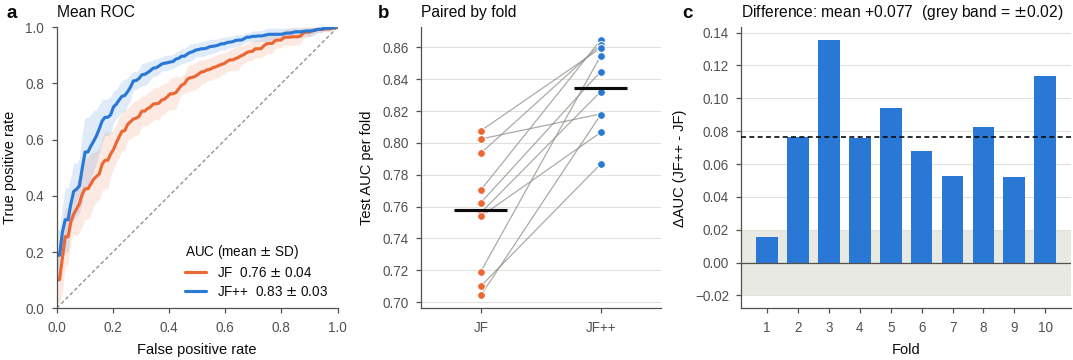

In [5]:
def mean_roc(ax, fpr, tprs, aucs, color, label):
    mu = tprs.mean(1); mu[-1] = 1; sd = tprs.std(1)
    ax.fill_between(fpr, np.clip(mu - sd, 0, 1), np.clip(mu + sd, 0, 1), color=color, alpha=.14, lw=0)
    ax.plot(fpr, mu, color=color, lw=1.5, label=f'{label}  {aucs.mean():.2f} $\pm$ {aucs.std(ddof=1):.2f}')

def performance_figure(P, title_suffix='', name=None):
    fig, ax = plt.subplots(1, 3, figsize=(FIG_W2, 62 * MM), layout='constrained', gridspec_kw={'width_ratios': [1, .8, 1.1]})
    for m in ('JF', 'JF++'):
        j = P[m]['joint']; mean_roc(ax[0], j['fpr'], j['tpr'], j['auc'], C_MODEL[m], m)
    ax[0].plot([0, 1], [0, 1], color=MUTED, lw=.6, ls=(0, (3, 2)))
    ax[0].set(xlabel='False positive rate', ylabel='True positive rate', xlim=(0, 1), ylim=(0, 1), aspect='equal')
    ax[0].legend(loc='lower right', title='AUC (mean $\pm$ SD)', title_fontsize=6.5, alignment='left'); ax[0].set_title('Mean ROC' + title_suffix)
    a, c = P['JF']['joint']['auc'], P['JF++']['joint']['auc']
    for x, y in zip(a, c): ax[1].plot([0, 1], [x, y], color=MUTED, lw=.6, alpha=.7, zorder=1)
    for i, (m, v) in enumerate((('JF', a), ('JF++', c))):
        ax[1].scatter(np.full(len(v), i), v, s=14, color=C_MODEL[m], edgecolor='white', lw=.5, zorder=3)
        ax[1].hlines(v.mean(), i - .22, i + .22, color=INK, lw=1.5, zorder=4)
    ax[1].set_xticks([0, 1], ['JF', 'JF++']); ax[1].set_xlim(-.5, 1.5); ax[1].set_ylabel('Test AUC per fold'); ygrid(ax[1]); ax[1].set_title('Paired by fold')
    d = c - a; f = np.arange(1, len(d) + 1)
    ax[2].axhspan(-.02, .02, color=GRID, alpha=.7, zorder=0, lw=0)
    ax[2].bar(f, d, color=np.where(d > 0, C_MODEL['JF++'], C_MODEL['JF']), width=.7, zorder=2)
    ax[2].axhline(d.mean(), color=INK, lw=.8, ls=(0, (3, 2)), zorder=3); ax[2].axhline(0, color=INK2, lw=.6)
    ax[2].set_xticks(f); ax[2].set_xlabel('Fold'); ax[2].set_ylabel('ΔAUC (JF++ - JF)'); ygrid(ax[2])
    ax[2].set_title(f'Difference: mean {d.mean():+.3f}  (grey band = $\pm$0.02)')
    for x, l in zip(ax, 'abc'): panel_label(x, l)
    if name: save_fig(fig, name)
    else: plt.show()

performance_figure(PERF, name='cmp_performance')

### 1.2 Per modality

Is a possible gain due to the graph (functional branch) or to the Transformer (structural branch)? Per-fold AUC of the structural-only, functional-only and joint models of both architectures.

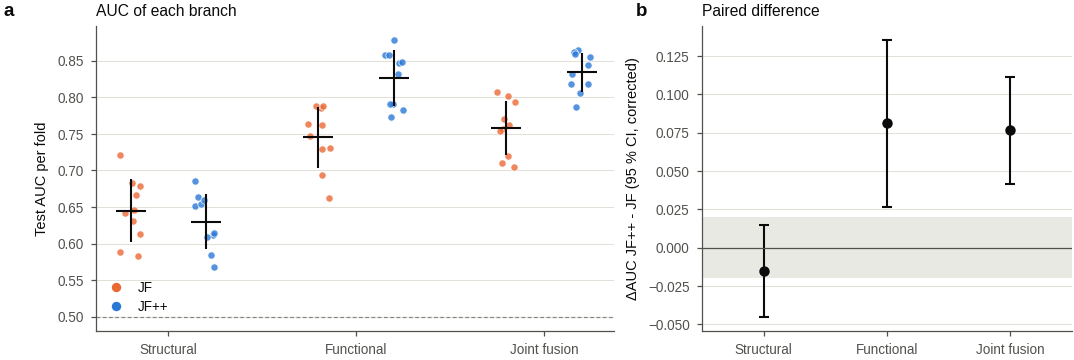

In [6]:
fig, ax = plt.subplots(1, 2, figsize=(FIG_W2, 62 * MM), layout='constrained', gridspec_kw={'width_ratios': [1.4, 1]})
rng = np.random.default_rng(0)
for i, b in enumerate(('struct', 'funct', 'joint')):
    for m, off in (('JF', -.2), ('JF++', .2)):
        v = PERF[m][b]['auc']
        ax[0].scatter(i + off + rng.uniform(-.06, .06, len(v)), v, s=12, color=C_MODEL[m], edgecolor='white', lw=.4, alpha=.8, zorder=3)
        ax[0].errorbar(i + off, v.mean(), v.std(ddof=1), fmt='_', color=INK, ms=14, capsize=0, elinewidth=1, zorder=4)
ax[0].axhline(.5, color=MUTED, lw=.6, ls=(0, (3, 2)))
ax[0].set_xticks(range(3), [BRANCH[b] for b in ('struct', 'funct', 'joint')]); ax[0].set_ylabel('Test AUC per fold'); ygrid(ax[0])
ax[0].legend(handles=[Line2D([], [], marker='o', ls='', color=C_MODEL[m], label=m) for m in C_MODEL], loc='center left', bbox_to_anchor=(0, 0.11))
for i, b in enumerate(('struct', 'funct', 'joint')):
    t = paired_tests(PERF['JF'][b]['auc'], PERF['JF++'][b]['auc'])
    ax[1].errorbar(i, t['mean diff'], yerr=[[t['mean diff'] - t['CI95 low']], [t['CI95 high'] - t['mean diff']]], fmt='o', color=INK, ms=4, capsize=2.5, lw=1)
ax[1].axhspan(-.02, .02, color=GRID, alpha=.7, lw=0, zorder=0); ax[1].axhline(0, color=INK2, lw=.6)
ax[1].set_xticks(range(3), [BRANCH[b] for b in ('struct', 'funct', 'joint')]); ax[1].set_xlim(-.5, 2.5)
ax[1].set_ylabel('ΔAUC JF++ - JF (95 % CI, corrected)'); ygrid(ax[1])
panel_label(ax[0], 'a'); panel_label(ax[1], 'b'); ax[0].set_title('AUC of each branch'); ax[1].set_title('Paired difference')
save_fig(fig, 'cmp_performance_modalities')

### So... _does the new model improve classification performance?_

...

<details>
<summary><b>Our answer</b></summary>

Yes: JF++ improves the classification performance, and the gain comes from the functional branch.

- **Joint model:** AUC 0.83 $\pm$ 0.03 (JF++) vs 0.76 $\pm$ 0.03 (JF), a difference of **+0.077** (95 % corrected CI +0.042 to +0.112), better in **10/10 folds** (corrected t-test p < 0.001, Wilcoxon p = 0.002). The TOST test rejects equivalence only if its p-value is small: here p $\approx$ 1, i.e. the two models are **not** equivalent within $\pm$0.02 AUC. 
- **Where the gain comes from:** functional-only AUC 0.75 $\rightarrow$ 0.83 (+0.08, 9/10 folds), structural-only AUC 0.65 $\rightarrow$ 0.63 (-0.015, not significant). The graph encoder on the connectome explains the improvement; the FT-Transformer on the 221 structural features does not beat the MLP.

</details>

# 2. What happens to the explanations?

Two models × two explanation methods:

| Label | Model | Method | File (in the results folder) |
|---|---|---|---|
| **JF SHAP** | JF | `GradientExplainer`, mean \|SHAP\| over the test subjects | `shap_value_joint_nested_{functional,morphological}_10kf.csv` |
| **JF++ SHAP** | JF++ | presence-**conditional** mean \|SHAP\| (only over the subjects whose kNN graph contains the connection) | `shap_value_joint_functional_conditional_10kf.csv`, `shap_value_jfpp_joint_morphological_10kf.csv` |
| **JF++ attention** | JF++ | first-layer GATv2 attention (conditional), `[CLS]` attention of the first Transformer block | `attention_value_joint_functional_conditional_10kf.csv`, `attention_value_joint_morphological_10kf.csv` |

> JF has not attention. Every file has one column per outer fold. For JF++ a connection absent from the graph of every test subject of a fold is `NaN`; connections present in **fewer than 5 %** of the test subjects in some fold are declared *not eligible* and ranked below all the others.

In [7]:
FF = pd.read_csv(os.path.join(DATA_IN, 'functional_features.csv'))
YEO = pd.read_csv(os.path.join(DATA_IN, 'ho_to_yeo_mapping.csv')).sort_values(['yeo_roi', 'ho_roi']).reset_index(drop=True)
CODES = YEO.ho_roi.to_numpy()
NET_NAME = YEO.yeo_label.str.replace('_Areas', '').str.replace('_Network', '').str.replace('_', ' ').to_numpy()
NET_ID = YEO.yeo_roi.to_numpy()
NETS = list(dict.fromkeys(NET_NAME))
NAME_OF = {**dict(zip(FF['ROI 1'], FF['r1'])), **dict(zip(FF['ROI 2'], FF['r2']))}
STRUCT_NAMES = list(pd.read_csv(os.path.join(DATA_IN, 'Harmonized_structural_features.csv'), nrows=1).columns[5:])
N_FUNC, N_STRUCT = len(FF), len(STRUCT_NAMES)
MIN_PRESENCE, TOP_FRAC = .05, .01

def fold_matrix(run, name):
    return pd.read_csv(os.path.join(RUN[run], f'{name}_10kf.csv'), index_col=0).abs().to_numpy(float)

RAW = {   # [n_features, n_folds]
    'JF SHAP':        {'f': fold_matrix('JF', 'shap_value_joint_nested_functional'),          's': fold_matrix('JF', 'shap_value_joint_nested_morphological')},
    'JF++ SHAP':      {'f': fold_matrix('JF++', 'shap_value_joint_functional_conditional'),   's': fold_matrix('JF++', 'shap_value_jfpp_joint_morphological')},
    'JF++ attention': {'f': fold_matrix('JF++', 'attention_value_joint_functional_conditional'), 's': fold_matrix('JF++', 'attention_value_joint_morphological')}}
PRES = fold_matrix('JF++', 'knn_presence_functional')
ELIG = {'JF SHAP': np.ones(N_FUNC, bool), 'JF++ SHAP': (PRES >= MIN_PRESENCE).all(1), 'JF++ attention': (PRES >= MIN_PRESENCE).all(1)}
print('eligible connections: JF %d / JF++ %d of %d' % (ELIG['JF SHAP'].sum(), ELIG['JF++ SHAP'].sum(), N_FUNC))
print('connections never present in some fold (JF++): %.1f %%' % (100 * (PRES.min(1) == 0).mean()))

def mean_rank(M, ok=None):
    # mean over folds of rank/N (1 = least important); NaN and not-eligible features ranked below all the others
    M = np.array(M, float); bad = ~np.isfinite(M)
    if ok is not None: bad |= ~ok[:, None]
    M[bad] = np.nanmin(M[~bad]) - 1
    return np.mean([stats.rankdata(M[:, i]) / M.shape[0] for i in range(M.shape[1])], axis=0)

RANK = {m: {'f': mean_rank(RAW[m]['f'], ELIG[m]), 's': mean_rank(RAW[m]['s'])} for m in RAW}
SCORE = {m: {'f': np.nanmean(RAW[m]['f'], 1), 's': np.nanmean(RAW[m]['s'], 1)} for m in RAW}     # fold-mean raw value
METHODS = list(RAW)

def rank_within(M, ok):
    # mean over folds of rank/n among the eligible features only (NaN elsewhere): same population for every method
    sub = np.array(M, float)[ok]; sub[~np.isfinite(sub)] = np.nanmin(sub[np.isfinite(sub)]) - 1
    out = np.full(len(ok), np.nan); out[ok] = np.mean([stats.rankdata(sub[:, i]) / len(sub) for i in range(sub.shape[1])], axis=0); return out
RANK_E = {m: rank_within(RAW[m]['f'], ELIG['JF++ SHAP']) for m in METHODS}      # re-ranked on the connections eligible in JF++

def functional_matrix(vec, fill=np.nan):
    idx = {c: i for i, c in enumerate(CODES)}
    M = np.full((len(CODES), len(CODES)), fill)
    for v, a, b in zip(vec, FF['ROI 1'], FF['ROI 2']):
        if a in idx and b in idx: M[idx[a], idx[b]] = M[idx[b], idx[a]] = v
    return M

def draw_matrix(ax, M, cmap, label, vmin=0, vmax=None, pct=99, cb=True):
    vmax = np.nanpercentile(M, pct) if vmax is None else vmax
    im = ax.imshow(M, cmap=cmap, vmin=vmin, vmax=vmax, interpolation='nearest')
    edges = np.flatnonzero(np.diff(NET_ID)) + 1
    for e in edges: ax.axhline(e - .5, color=INK, lw=.3); ax.axvline(e - .5, color=INK, lw=.3)
    b = np.r_[0, edges, len(NET_ID)]; mid = (b[:-1] + b[1:]) / 2 - .5
    ax.set_xticks(mid, [NET_NAME[int(i)] for i in b[:-1]], rotation=90, fontsize=5.5); ax.set_yticks(mid, [NET_NAME[int(i)] for i in b[:-1]], fontsize=5.5)
    ax.tick_params(length=0)
    for s in ax.spines.values(): s.set_visible(True)
    if cb:
        c = plt.colorbar(im, ax=ax, fraction=.046, pad=.03); c.set_label(label, fontsize=6); c.ax.tick_params(labelsize=5)
    return im

eligible connections: JF 5253 / JF++ 237 of 5253
connections never present in some fold (JF++): 89.9 %


### 2.1 Importance matrices, organised in networks

ROI × ROI matrices (regions grouped by Yeo network, `ho_to_yeo_mapping.csv`) of the three explanations. Top row: the **fold-mean raw value** of each method (colour scale clipped at the 99th percentile; white = not eligible or never present). Bottom row: the same connections as **mean rank**, which puts the three methods on a common 0–1 scale.

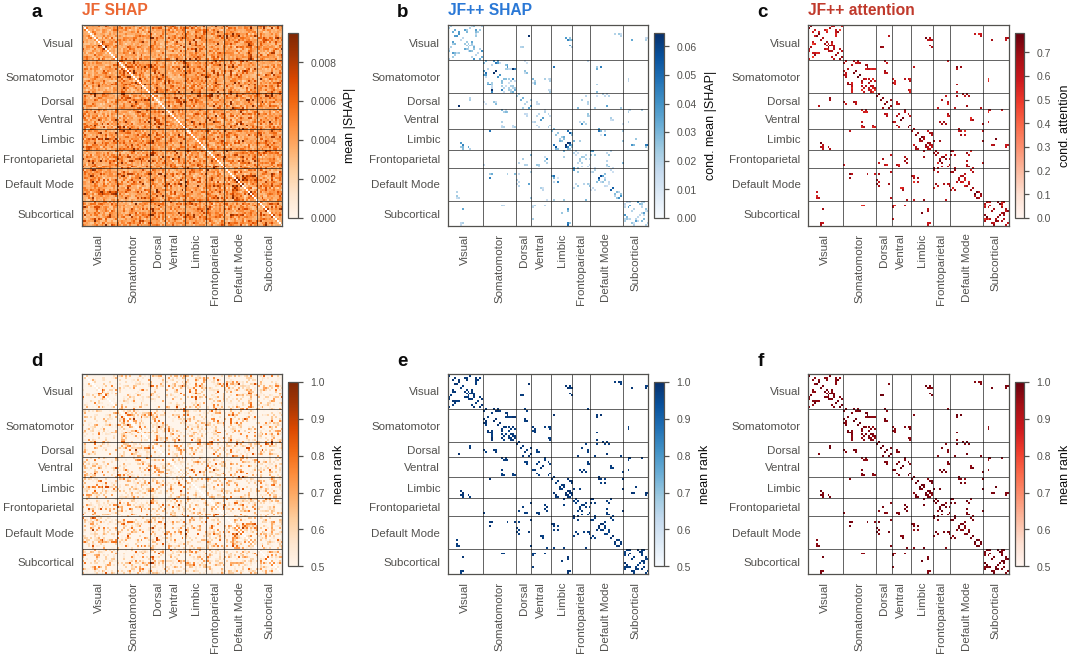

In [8]:
CM = {'JF SHAP': 'Oranges', 'JF++ SHAP': 'Blues', 'JF++ attention': 'Reds'}
fig, ax = plt.subplots(2, 3, figsize=(FIG_W2, 118 * MM), layout='constrained')
for j, m in enumerate(METHODS):
    v = np.where(ELIG[m], SCORE[m]['f'], np.nan)
    draw_matrix(ax[0, j], functional_matrix(v), CM[m], {'JF SHAP': 'mean |SHAP|', 'JF++ SHAP': 'cond. mean |SHAP|', 'JF++ attention': 'cond. attention'}[m])
    ax[0, j].set_title(m, color=C_METHOD[m], fontweight='bold')
    r = np.where(ELIG[m], RANK[m]['f'], np.nan)
    draw_matrix(ax[1, j], functional_matrix(r), CM[m], 'mean rank', vmin=.5, vmax=1, cb=True)
for x, l in zip(ax.ravel(), 'abcdef'): panel_label(x, l, x=-.25)
save_fig(fig, 'cmp_matrices')

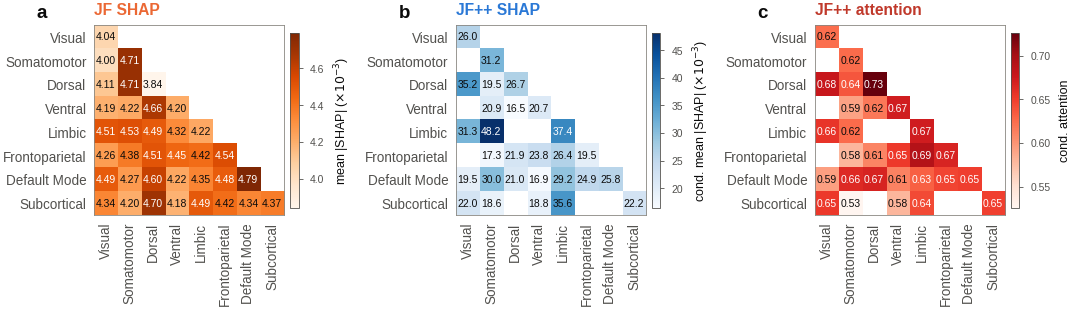

In [9]:
def block_matrix(vals, ok):
    # mean of `vals` over the eligible connections of each pair of networks
    idx = {c: i for i, c in enumerate(CODES)}
    nets = {n: k for k, n in enumerate(NETS)}
    S, C = np.zeros((len(NETS), len(NETS))), np.zeros((len(NETS), len(NETS)))
    for v, a, b, o in zip(vals, FF['ROI 1'], FF['ROI 2'], ok):
        if a in idx and b in idx and o and np.isfinite(v):
            i, j = nets[NET_NAME[idx[a]]], nets[NET_NAME[idx[b]]]
            for p, q in ((i, j), (j, i)) if i != j else ((i, j),):
                S[p, q] += v; C[p, q] += 1
    return np.divide(S, C, out=np.full_like(S, np.nan), where=C > 0)

CB_LABEL = {'JF SHAP': 'mean |SHAP| ($\\times10^{-3}$)', 'JF++ SHAP': 'cond. mean |SHAP| ($\\times10^{-3}$)', 'JF++ attention': 'cond. attention'}
SCALE = {'JF SHAP': 1e-3, 'JF++ SHAP': 1e-3, 'JF++ attention': 1}     # display units, keeps the cell labels short
FMT = {'JF SHAP': '.2f', 'JF++ SHAP': '.1f', 'JF++ attention': '.2f'}
LOWER = np.tril(np.ones((len(NETS), len(NETS)), bool))          # the block matrix is symmetric: show the lower triangle only
BLOCK = {m: np.where(LOWER, block_matrix(SCORE[m]['f'], ELIG[m]), np.nan) for m in METHODS}

fig, ax = plt.subplots(1, 3, figsize=(FIG_W2, 62 * MM), layout='constrained')
for a, m in zip(ax, METHODS):
    M = BLOCK[m] / SCALE[m]
    lo, hi = np.nanmin(M), np.nanmax(M)
    norm = mpl.colors.Normalize(lo, hi)                          # each panel spans its own range: structure stays visible
    im = a.imshow(M, cmap=CM[m], norm=norm, interpolation='nearest')
    a.set_xticks(range(len(NETS)), NETS, rotation=90); a.set_yticks(range(len(NETS)), NETS)
    a.tick_params(length=0)
    for s_ in a.spines.values(): s_.set_visible(True); s_.set_linewidth(0.4); s_.set_color(MUTED)
    cmap = mpl.colormaps[CM[m]]
    for (i, j), v in np.ndenumerate(M):
        if np.isfinite(v):                                       # black / white label chosen from the cell luminance
            r, g, b, _ = cmap(norm(v)); lum = .2126 * r + .7152 * g + .0722 * b
            a.text(j, i, format(v, FMT[m]), ha='center', va='center', fontsize=5, color='white' if lum < .5 else INK)
    a.set_title(m, color=C_METHOD[m], fontweight='bold')
    cb = fig.colorbar(im, ax=a, fraction=.046, pad=.03)
    cb.set_label(CB_LABEL[m], fontsize=6); cb.ax.tick_params(labelsize=5, width=.4, length=2)
    cb.outline.set_linewidth(.4)
for x, l in zip(ax, 'abc'): panel_label(x, l, x=-.3)
save_fig(fig, 'cmp_network_blocks')


**Structural features.** The same comparison for the 221 morphological features: mean rank of the top-10 features of each method, side by side (colour = method; the feature is drawn for all three methods so the rank change is visible).

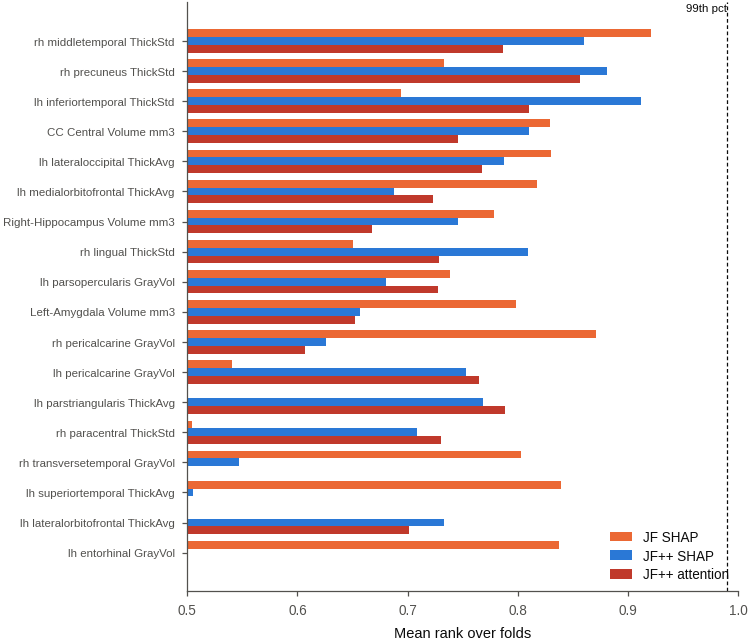

In [10]:
top = []
for m in METHODS: top += list(np.argsort(-RANK[m]['s'])[:10])
top = list(dict.fromkeys(top))
top = sorted(top, key=lambda i: -np.mean([RANK[m]['s'][i] for m in METHODS]))
fig, ax = plt.subplots(figsize=(FIG_W2 * .7, 38 * MM + 4 * len(top) * MM), layout='constrained')
h = .26
for j, m in enumerate(METHODS):
    ax.barh(np.arange(len(top)) + (j - 1) * h, [RANK[m]['s'][i] for i in top], height=h, color=C_METHOD[m], label=m)
ax.set_yticks(range(len(top)), [STRUCT_NAMES[i].replace('_', ' ') for i in top], fontsize=5.5); ax.invert_yaxis()
ax.axvline(.99, color=INK, lw=.6, ls=(0, (3, 2))); ax.text(.99, -.9, '99th pct', ha='right', va='bottom', fontsize=5.5)
ax.set_xlim(.5, 1.0); ax.set_xlabel('Mean rank over folds')
ax.legend(loc='lower right', edgecolor='white')
save_fig(fig, 'cmp_structural_ranks')

### 2.3 The 99th percentile: crucial connections and regions

A connection is **crucial** if its mean rank is in the top 1 % (99th percentile) of the 5253 connections, i.e. the top $\lceil 0.01 \times 5253\rceil = 53$ connections; not-eligible connections cannot be crucial. The same is done for the structural features (top 1 % of 221 = 2 features). Below: (a) the overlap of the crucial sets of the three explanations, (b) the circular connectome of the crucial connections of each explanation (regions grouped by Yeo network), and (c) the regions that take part in most crucial connections.

In [11]:
def crucial(score, frac=TOP_FRAC):
    k = max(1, int(round(frac * len(score)))); m = np.zeros(len(score), bool); m[np.argsort(-score)[:k]] = True; return m

CRU = {m: crucial(RANK[m]['f']) for m in METHODS}
CRU_S = {m: crucial(RANK[m]['s']) for m in METHODS}
print('crucial connections per method:', {m: int(v.sum()) for m, v in CRU.items()}, '| structural:', {m: int(v.sum()) for m, v in CRU_S.items()})

# overlap table
ov = pd.DataFrame([[int((CRU[a] & CRU[b]).sum()) for b in METHODS] for a in METHODS], index=METHODS, columns=METHODS)
print('Overlap (number of connections in both crucial sets):'); display(ov)
shared = [f for f in np.flatnonzero(CRU['JF SHAP'] | CRU['JF++ SHAP'] | CRU['JF++ attention']) if sum(CRU[m][f] for m in METHODS) > 1]
print('connections crucial in at least two explanations:')
display(pd.DataFrame({'region 1': FF['r1'].to_numpy()[shared], 'region 2': FF['r2'].to_numpy()[shared],
                      **{m: CRU[m][shared] for m in METHODS}}) if shared else 'none')
print('crucial structural features:')
display(pd.DataFrame({m: [STRUCT_NAMES[i] for i in np.flatnonzero(CRU_S[m])] for m in METHODS}))

crucial connections per method: {'JF SHAP': 53, 'JF++ SHAP': 53, 'JF++ attention': 53} | structural: {'JF SHAP': 2, 'JF++ SHAP': 2, 'JF++ attention': 2}
Overlap (number of connections in both crucial sets):


,JF SHAP,JF++ SHAP,JF++ attention
JF SHAP,53,0,0
JF++ SHAP,0,53,16
JF++ attention,0,16,53


connections crucial in at least two explanations:


,region 1,region 2,JF SHAP,JF++ SHAP,JF++ attention
0,Right Frontal Pole,Left Frontal Pole,False,True,True
1,"Left Lateral Occipital Cortex, superior division","Right Lateral Occipital Cortex, superior division",False,True,True
2,Left Postcentral Gyrus,Right Postcentral Gyrus,False,True,True
3,Right Occipital Pole,Left Occipital Pole,False,True,True
4,Left Thalamus,Right Thalamus,False,True,True
5,Right Paracingulate Gyrus,Left Paracingulate Gyrus,False,True,True
6,"Right Cingulate Gyrus, anterior division","Left Cingulate Gyrus, anterior division",False,True,True
7,"Right Parahippocampal Gyrus, anterior division","Left Parahippocampal Gyrus, anterior division",False,True,True
8,Right Juxtapositional Lobule Cortex (formerly ...,Left Juxtapositional Lobule Cortex (formerly S...,False,True,True
9,Right Cuneal Cortex,Left Cuneal Cortex,False,True,True


crucial structural features:


,JF SHAP,JF++ SHAP,JF++ attention
0,rh_middletemporal_ThickStd,lh_inferiortemporal_ThickStd,lh_inferiortemporal_ThickStd
1,rh_pericalcarine_GrayVol,rh_precuneus_ThickStd,rh_precuneus_ThickStd


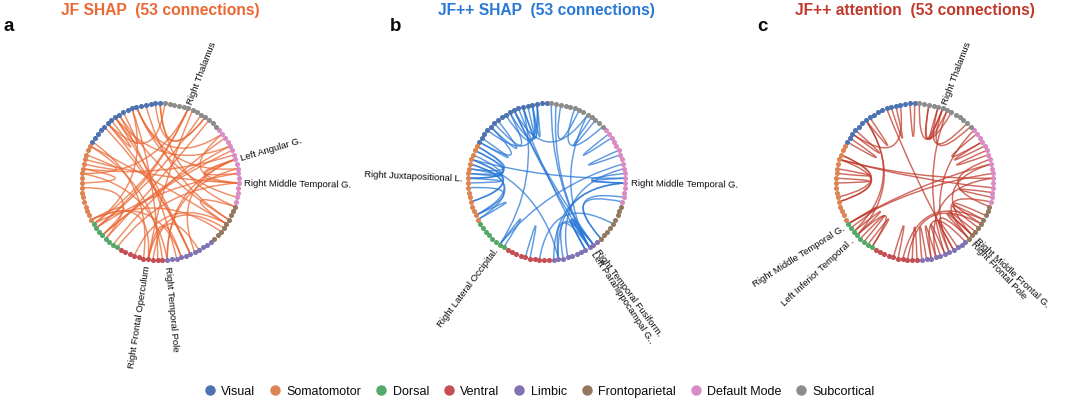

In [12]:
NET_COL = dict(zip(NETS, ['#4c72b0', '#dd8452', '#55a868', '#c44e52', '#8172b3', '#937860', '#da8bc3', '#8c8c8c', '#ccb974', '#64b5cd']))
ang = {c: 2 * np.pi * i / len(CODES) + np.pi / 2 for i, c in enumerate(CODES)}
pos = {c: np.array([np.cos(a), np.sin(a)]) for c, a in ang.items()}
node_net = dict(zip(CODES, NET_NAME))
SHORT = lambda n: (n.replace(', posterior division', ' post.').replace(', anterior division', ' ant.').replace(' Gyrus', ' G.').replace(' Cortex', '')
                   .replace(', superior division', ' sup.').replace(', inferior division', ' inf.').replace('Temporooccipital', 'Temp-occ.'))

def draw_circle(ax, crucial_mask, color, title):
    for c in CODES: ax.scatter(*pos[c], s=6, color=NET_COL[node_net[c]], zorder=3, lw=0)
    deg = {}
    for f in np.flatnonzero(crucial_mask):
        a, b = FF['ROI 1'][f], FF['ROI 2'][f]
        if a not in pos or b not in pos: continue
        p0, p1 = pos[a], pos[b]; ctrl = (p0 + p1) / 2 * .15
        ax.add_patch(PathPatch(Path([p0, ctrl, p1], [Path.MOVETO, Path.CURVE3, Path.CURVE3]), fc='none', ec=color, lw=.7, alpha=.75, zorder=2))
        deg[a] = deg.get(a, 0) + 1; deg[b] = deg.get(b, 0) + 1
    for c, d in sorted(deg.items(), key=lambda t: -t[1])[:5]:      # label the 5 regions with most crucial connections
        a = ang[c]; rot = np.degrees(a) % 360; flip = 90 < rot < 270
        lab = SHORT(NAME_OF[c]); lab = lab if len(lab) <= 24 else lab[:23] + '.'
        ax.text(1.07 * np.cos(a), 1.07 * np.sin(a), lab, fontsize=4.6, rotation=rot - 180 if flip else rot, ha='right' if flip else 'left', va='center', rotation_mode='anchor')
    ax.set_xlim(-2.0, 2.0); ax.set_ylim(-2.0, 2.0); ax.set_aspect('equal'); ax.axis('off')
    ax.set_title(f'{title}  ({int(crucial_mask.sum())} connections)', color=color, fontweight='bold', loc='center')
    return deg

fig, ax = plt.subplots(1, 3, figsize=(FIG_W2, 70 * MM), layout='constrained')
DEG = {m: draw_circle(a, CRU[m], C_METHOD[m], m) for a, m in zip(ax, METHODS)}
fig.legend(handles=[Line2D([], [], marker='o', ls='', color=NET_COL[n], ms=4, label=n) for n in NETS], loc='outside lower center', ncol=len(NETS), fontsize=6, handletextpad=.1, columnspacing=.8)
for x, l in zip(ax, 'abc'): panel_label(x, l, x=0, y=.97)
save_fig(fig, 'cmp_crucial_circles')

In [13]:
rows = {}
for m in METHODS:
    d = pd.Series(DEG[m]).sort_values(ascending=False)
    rows[m] = [f'{SHORT(NAME_OF[c])} ({n})' for c, n in d.head(8).items()]
print('Regions with the most crucial connections (number of crucial connections in brackets):')
display(pd.DataFrame(rows, index=range(1, 9)))
common = set(DEG['JF SHAP']) & set(DEG['JF++ SHAP']) & set(DEG['JF++ attention'])
print('regions involved in the crucial connections of all three explanations:', sorted(SHORT(NAME_OF[c]) for c in common) or 'none')
net_count = pd.DataFrame({m: pd.Series([node_net[a] for f in np.flatnonzero(CRU[m]) for a in (FF['ROI 1'][f], FF['ROI 2'][f]) if a in node_net]).value_counts() for m in METHODS}).reindex(NETS).fillna(0).astype(int)
print('endpoints of the crucial connections per Yeo network:'); display(net_count)

Regions with the most crucial connections (number of crucial connections in brackets):


,JF SHAP,JF++ SHAP,JF++ attention
1,Left Angular G. (4),Left Parahippocampal G. ant. (7),Right Frontal Pole (3)
2,Right Frontal Operculum (4),Right Middle Temporal G. ant. (4),Right Middle Frontal G. (3)
3,Right Middle Temporal G. ant. (4),Right Temporal Fusiform post. (4),Left Temporal Occipital Fusiform (3)
4,Right Temporal Pole (3),Right Juxtapositional Lobule (formerly Supplem...,"Left Inferior Temporal G., temporooccipital pa..."
5,"Left Inferior Temporal G., temporooccipital pa...",Right Intracalcarine (3),Right Thalamus (3)
6,"Left Middle Temporal G., temporooccipital part...",Right Planum Temporale (3),Left Superior Temporal G. ant. (3)
7,Right Temporal Occipital Fusiform (3),Left Intracalcarine (3),"Right Middle Temporal G., temporooccipital par..."
8,Left Cuneal (3),Left Cuneal (3),Left Lateral Occipital sup. (2)


regions involved in the crucial connections of all three explanations: ['Left Accumbens', 'Left Cingulate G. ant.', 'Left Cuneal', 'Left Frontal Operculum', 'Left Inferior Frontal G., pars triangularis', 'Left Inferior Temporal G. post.', 'Left Intracalcarine', 'Left Juxtapositional Lobule (formerly Supplementary Motor)', 'Left Lateral Occipital sup.', 'Left Occipital Pole', 'Left Paracingulate G.', 'Left Postcentral G.', 'Left Precuneous', 'Left Superior Temporal G. ant.', 'Left Temporal Occipital Fusiform', 'Right Amygdala', 'Right Inferior Temporal G. post.', 'Right Lateral Occipital sup.', 'Right Middle Temporal G. post.', 'Right Paracingulate G.', 'Right Parahippocampal G. ant.', 'Right Parahippocampal G. post.', 'Right Postcentral G.', 'Right Superior Frontal G.', 'Right Superior Temporal G. ant.', 'Right Temporal Pole', 'Right Thalamus']
endpoints of the crucial connections per Yeo network:


,JF SHAP,JF++ SHAP,JF++ attention
Visual,21,25,15
Somatomotor,14,26,12
Dorsal,13,4,14
Ventral,9,3,6
Limbic,11,20,15
Frontoparietal,9,3,14
Default Mode,20,15,17
Subcortical,9,10,13


### Again... _What happens to the explanations of the two models, and how do they change between attention and SHAP?_

...

<details>
<summary><b>Our answer</b></summary>

**The explanation changes a lot when the model changes, and attention and SHAP are two different views even inside JF++.** 

*Between the models (JF SHAP $\rightarrow$ JF++ SHAP).*
* JF explains the whole connectome: every one of the 5253 connections is always an input and its SHAP is a diffuse, low-contrast mosaic (matrix **a**). JF++ with the kNN-strict graph (`k = 1`) only *sees* the strongest connection of each region, so only **237 of 5253** connections are eligible (present in ≥ 5 % of the test subjects in every fold) and its explanation is concentrated **inside the Yeo networks** (blocks on the diagonal of matrices **b**, **c**, **e**, **f**): the model mostly reads short, within-network links.
* The two rankings of the connections are essentially **unrelated** (Spearman ρ = -0.06 on the eligible connections; the crucial top 1 % (53 connections) of JF SHAP and JF++ SHAP share **0** connections; restricted to the 237 shared connections the top-10 % overlap is 0.04, at chance level 0.05). The rank-difference matrices (Section 2.2, **a**, **c**) show the rank changes in both directions in every network block. Some regions do appear in both models' crucial sets (e.g. right anterior middle temporal gyrus, left cuneal cortex), but through different connections.
* For the **structural** features the change is milder: JF SHAP and JF++ SHAP correlate at ρ = 0.38, and the two JF++ read-outs pick *lh inferior temporal* and *rh precuneus* thickness variability, JF picks *rh middle temporal* thickness variability and *rh pericalcarine* volume.
* Reproducibility across folds is low for JF SHAP (mean between-fold ρ = 0.13) and higher for JF++ SHAP (0.33), which is partly the effect of the sparse graph: the explanation is restricted to a smaller, more stable set of connections.

*Between the methods (JF++ SHAP vs attention).*
* On the **connections** the agreement is weak but above chance: ρ = 0.18, 16 of the 53 crucial connections are shared (Jaccard 0.18 vs 0.005 expected by chance), while on the 237 eligible connections the top-10 % overlap is only 0.07. Attention is far more stable across folds (between-fold ρ = 0.73 vs 0.33 for SHAP) but this stability is not agreement with the output: attention only tells how the first GAT layer weights neighbours (Jain & Wallace 2019).
* On the **structural** features the two methods agree strongly (ρ = 0.88, top-10 Jaccard 0.67): the `[CLS]` attention of the first Transformer block behaves like a good proxy of SHAP there, while it does not for the graph.
* At the level of **networks** the crucial connections of JF++ SHAP are concentrated in Visual and Somatomotor (25 + 26 of 106 endpoints) and Limbic, attention is spread more evenly (Dorsal, Frontoparietal, Default Mode and Subcortical are more represented), JF SHAP is spread over Visual and Default Mode.

**Take-home.** An explanation is a property of the *pair* (model, method): switching MLP $\rightarrow$ graph/Transformer or SHAP $\rightarrow$ attention changes which connections look important. Only the connections/regions that are crucial under several explanations (Section 2.3, 16 connections shared by the JF++ explanations and the regions involved in all three) deserve a neurobiological reading, and the 99th-percentile sets of such different explanations should be reported together with their agreement.

</details>

# 3. What is the computational cost of JF++ compared to JF?

Computational cost was implemented looking at three different measures during the training phase. Specifically, we use an hardware-indipendent measure for quantify the number of floating-point operation for each subject and two codecarbon-based measures for energy consumption and CO $_2$ e emission.

- **MFLOPs**: hardware-independent forward cost per subject (`FlopCounterMode` + analytic GATv2 edge work), median over folds; the cost of a training step is roughly 3× the forward cost;
- **kWh**: measured energy of the training of the fold, split by hardware component (**GPU**, **CPU**, **RAM**);
- **CO $_2$ e** (g): kWh × PUE × carbon intensity (CI), with PUE = 1 and CI = 250 gCO $_2$ /kWh.

Energy and CO $_2$ e are summed over the 10 outer folds (one training per fold) and also shown per fold.

In [14]:
CI, PUE = 250.0, 1.0 # gCO2/kWh, power usage effectiveness (they can change according to hardware or part of the world)
cc = pd.read_csv(os.path.join(COMP, 'computational_cost_per_fold.csv'))
cc = cc[cc.run.isin([JF_RUN, JFPP_RUN])].copy()
cc['label'] = cc.run.map({JF_RUN: 'JF', JFPP_RUN: 'JF++'})
COMP = [('gpu', 'GPU'), ('cpu', 'CPU'), ('ram', 'RAM')]
for c, _ in COMP:
    cc[f'train_gCO2_{c}'] = cc[f'train_kWh_{c}'] * PUE * CI
cc['train_kWh_total'] = cc[[f'train_kWh_{c}' for c, _ in COMP]].sum(1)
cc['train_gCO2_total'] = cc.train_kWh_total * PUE * CI
print('folds per model:', cc.groupby('label').size().to_dict())

g = cc.groupby('label')
tab = pd.DataFrame({'Parameters (median)': g.params.median(), 'MFLOPs / subject (median)': g.mflops_per_subject.median(),
                    'Training time [s] (sum)': g.train_s.sum(), 'Epochs (mean)': g.epochs.mean(),
                    **{f'{n} [kWh]': g[f'train_kWh_{c}'].sum() for c, n in COMP}, 'Total [kWh]': g.train_kWh_total.sum(),
                    **{f'{n} [gCO2e]': g[f'train_gCO2_{c}'].sum() for c, n in COMP}, 'Total [gCO2e]': g.train_gCO2_total.sum()}).loc[['JF', 'JF++']]
ratio = (tab.loc['JF++'] / tab.loc['JF']).rename('JF++ / JF')
display(pd.concat([tab.T, ratio], axis=1).style.format({'JF': '{:.4g}', 'JF++': '{:.4g}', 'JF++ / JF': '{:.2f}×'}))

folds per model: {'JF': 10, 'JF++': 10}


,JF,JF++,JF++ / JF
Parameters (median),3.526e+05,1.847e+05,0.52×
MFLOPs / subject (median),0.7037,51.87,73.70×
Training time [s] (sum),82.06,92.12,1.12×
Epochs (mean),29.8,24.2,0.81×
GPU [kWh],0.0009572,0.002468,2.58×
CPU [kWh],0.0007521,0.0008393,1.12×
RAM [kWh],0.001692,0.001888,1.12×
Total [kWh],0.003401,0.005196,1.53×
GPU [gCO2e],0.2393,0.617,2.58×
CPU [gCO2e],0.188,0.2098,1.12×


### 3.1 Training energy and CO $_2$ e per hardware component

**a** hardware-independent cost (MFLOPs per subject, one dot per fold, log axis).

**b** energy of the training of one fold (kWh),

**c** its CO $_2$ e (g), for GPU, CPU and RAM (box = 10 outer folds). Bars below: the sum over the 10 folds.

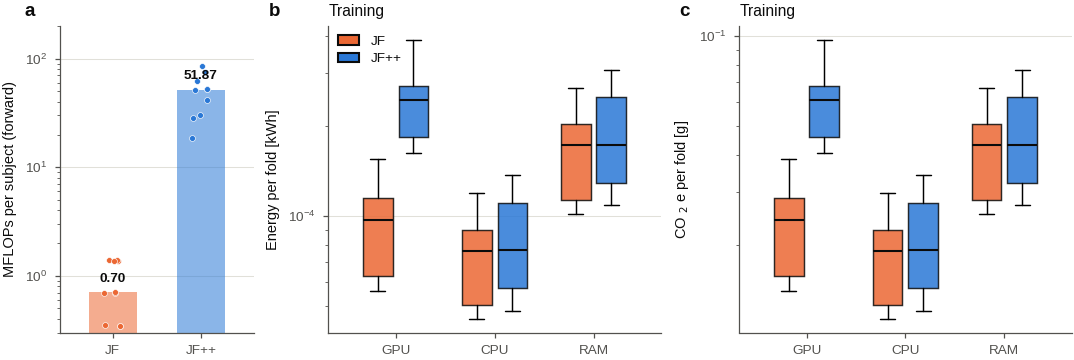

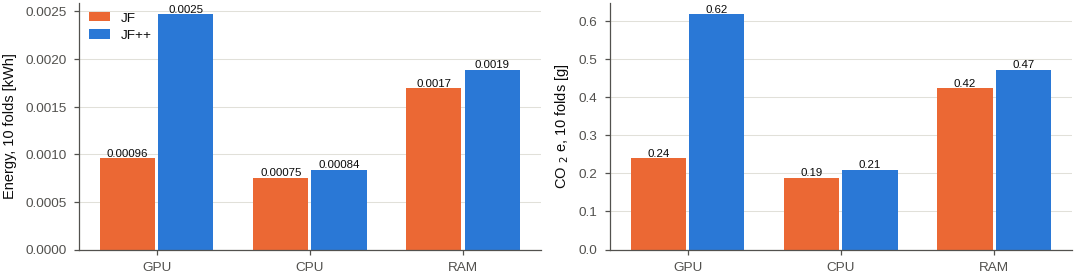

In [15]:
fig, ax = plt.subplots(1, 3, figsize=(FIG_W2, 62 * MM), layout='constrained', gridspec_kw={'width_ratios': [.7, 1.2, 1.2]})
rng = np.random.default_rng(0)
for i, m in enumerate(('JF', 'JF++')):
    v = cc[cc.label == m].mflops_per_subject.to_numpy()
    ax[0].bar(i, np.median(v), color=C_MODEL[m], width=.55, alpha=.55, zorder=2)
    ax[0].scatter(i + rng.uniform(-.1, .1, len(v)), v, s=8, color=C_MODEL[m], edgecolor='white', lw=.3, zorder=3)
    ax[0].text(i, np.median(v) * 1.25, f'{np.median(v):.2f}', ha='center', fontsize=6.5, fontweight='bold')
ax[0].set_yscale('log'); ax[0].set_xticks([0, 1], ['JF', 'JF++']); ax[0].set_ylabel('MFLOPs per subject (forward)'); ax[0].set_xlim(-.6, 1.6); ax[0].set_ylim(.3, 200); ygrid(ax[0])
for a, (qty, unit) in zip(ax[1:], (('kWh', 'Energy per fold [kWh]'), ('gCO2', 'CO $_2$ e per fold [g]'))):
    for j, (c, n) in enumerate(COMP):
        for i, m in enumerate(('JF', 'JF++')):
            v = cc[cc.label == m][f'train_{qty}_{c}'].dropna().to_numpy()
            bp = a.boxplot(v, positions=[j + (i - .5) * .36], widths=.3, patch_artist=True, showfliers=True,
                           flierprops=dict(marker='.', ms=3, mfc=INK, mec='none'), medianprops=dict(color=INK, lw=1), whiskerprops=dict(lw=.7), capprops=dict(lw=.7), boxprops=dict(lw=.7))
            bp['boxes'][0].set(facecolor=C_MODEL[m], edgecolor=INK, alpha=.85)
    a.set_yscale('log'); a.set_xticks(range(3), [n for _, n in COMP]); a.set_ylabel(unit); ygrid(a)
ax[1].legend(handles=[Patch(facecolor=C_MODEL[m], edgecolor=INK, label=m) for m in C_MODEL], loc='upper left')
ax[1].set_title('Training'); ax[2].set_title('Training')
for x, l in zip(ax, 'abc'): panel_label(x, l)
save_fig(fig, 'cmp_cost_training')

fig, ax = plt.subplots(1, 2, figsize=(FIG_W2, 48 * MM), layout='constrained')
for a, (qty, unit) in zip(ax, (('kWh', 'Energy, 10 folds [kWh]'), ('gCO2', 'CO $_2$ e, 10 folds [g]'))):
    for j, (c, n) in enumerate(COMP):
        for i, m in enumerate(('JF', 'JF++')):
            s = cc[cc.label == m][f'train_{qty}_{c}'].sum()
            a.bar(j + (i - .5) * .38, s, width=.36, color=C_MODEL[m], label=m if j == 0 else None)
            a.text(j + (i - .5) * .38, s, f'{s:.2g}', ha='center', va='bottom', fontsize=5.5)
    a.set_xticks(range(3), [n for _, n in COMP]); a.set_ylabel(unit); ygrid(a)
ax[0].legend(loc='upper left')
save_fig(fig, 'cmp_cost_training_totals')

### 3.2 Is the energy proportional to the FLOPs?

FLOPs measure operations the model needs; the energy also contains the cost of keeping the machine on (CPU and RAM during a short training are dominated by the idle power). The cell below gives the ratios JF++ / JF of the different quantities.

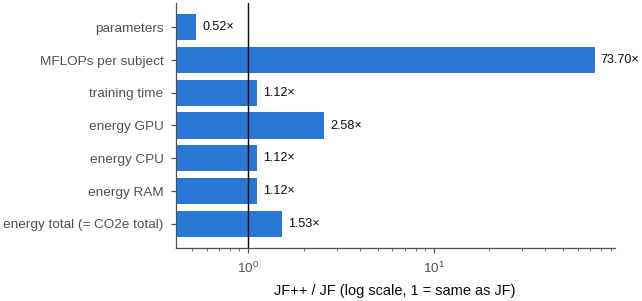

In [16]:
r = pd.Series({'parameters': tab.loc['JF++', 'Parameters (median)'] / tab.loc['JF', 'Parameters (median)'],
               'MFLOPs per subject': tab.loc['JF++', 'MFLOPs / subject (median)'] / tab.loc['JF', 'MFLOPs / subject (median)'],
               'training time': tab.loc['JF++', 'Training time [s] (sum)'] / tab.loc['JF', 'Training time [s] (sum)'],
               'energy GPU': tab.loc['JF++', 'GPU [kWh]'] / tab.loc['JF', 'GPU [kWh]'], 'energy CPU': tab.loc['JF++', 'CPU [kWh]'] / tab.loc['JF', 'CPU [kWh]'],
               'energy RAM': tab.loc['JF++', 'RAM [kWh]'] / tab.loc['JF', 'RAM [kWh]'], 'energy total (= CO2e total)': tab.loc['JF++', 'Total [kWh]'] / tab.loc['JF', 'Total [kWh]']})
fig, ax = plt.subplots(figsize=(FIG_W2 * .6, 52 * MM), layout='constrained')
ax.barh(range(len(r)), r.values, color=[C_MODEL['JF++']] * len(r)); ax.set_xscale('log'); ax.axvline(1, color=INK, lw=.7)
ax.set_yticks(range(len(r)), r.index); ax.invert_yaxis(); ax.set_xlabel('JF++ / JF (log scale, 1 = same as JF)')
for i, v in enumerate(r.values): ax.text(v * 1.08, i, f'{v:.2f}×', va='center', fontsize=6)
save_fig(fig, 'cmp_cost_ratios')

### Finally... _What is the computational cost of the new model compared to the current one?_

...

<details>
<summary><b>Our answer</b></summary>

**JF++ needs about 74× more arithmetic per subject but only ≈ 1.5× the training energy; in absolute terms both costs are tiny.** (Training phase only, summed over the 10 outer folds, CI = 250 gCO$_2$/kWh, PUE = 1.)

| | JF | JF++ | JF++ / JF |
|---|---|---|---|
| MFLOPs per subject (forward, median) | 0.70 | 51.9 | **74×** |
| Trainable parameters (median) | 352 k | 185 k | 0.52× |
| Energy GPU / CPU / RAM [Wh] | 0.96 / 0.75 / 1.69 | 2.47 / 0.84 / 1.89 | 2.6× / 1.1× / 1.1× |
| Total energy [kWh] | 0.0034 | 0.0052 | **1.5×** |
| CO $_2$ e [g] | 0.85 | 1.30 | **1.5×** |

* The extra cost is concentrated on the **GPU** (2.6×): the graph attention over the subject graphs is the expensive part. CPU and RAM energy are essentially unchanged because they are dominated by the time the machine is on, and the training time per fold is similar (1.12×; JF++ also converges in fewer epochs, 24 vs 30).
* FLOPs therefore overstate the cost of JF++ in practice for this small problem, but would dominate with larger graphs: the kNN-strict graph of this run has about 80 edges per subject (mean degree 1.55), the complete graph has 5253.
* These figures are for **training one model per fold**. They do not include the hyperparameter search (the most expensive phase for both models) nor the explanations: SHAP needs more than 24 GB of VRAM for the complete JF++ graph, and a few minutes per fold on a GPU for kNN-strict (Joint_Fusion_pp.ipynb, Section 11).
* **Is it worth it?** A +0.077 AUC gain (Section 1) for +1.5× training energy (~0.45 g CO $_2$ e over ten trainings) is a favourable trade-off for this task, whatever the carbon intensity of the grid, since the ratio does not depend on it.

</details>